# 04 · Ensemble, tuning, SHAP, weather model (E7–E10)

Carried forward from notebooks 02 and 03:
- **Target and training:** trend + residual target, `obs` (ERA5) training weather, Uri excluded, default features (no humidity or precipitation).
- **Champion rule:** among candidates whose Peak-MAPE beats the floor (6.50%), take the lowest MAPE. Differences under 0.1 points count as a tie, and the tie goes to the better Peak-MAPE.
- Under that rule, **LightGBM + trend** (4.85% / 3.64%) leads CatBoost + trend (4.84% / 3.75%).

| # | Question |
|---|---|
| E7 | Does a weighted blend of the trees and the LSTM beat the best single model? Weights are fitted leave-one-fold-out, so the score is honest. |
| E8 | How much does Optuna tuning add to LightGBM? (40 trials, same folds) |
| E9 | What drives the model, and what does it miss in the hard 2023–24 fold? Can SHAP prune features? |
| E10 | Archived forecasts from Open-Meteo's `best_match` blend vs one fixed model, `gfs_seamless`. |

In [1]:
%matplotlib inline
import time, warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import optuna, shap
from datetime import date
from shef import store
from shef.config import REPORTS
from shef.features.replay import replay
from shef.models import cv, data, ensemble, gbdt, plots, report, tracking, weather_variants
from shef.models.metrics import score_folds

FLOOR_PEAK = 6.50
mlflow = tracking.init()
features = data.default_features()
tables = data.load_tables(features)
optuna.logging.set_verbosity(optuna.logging.WARNING)

## E7 · Ensemble

Out-of-fold predictions are loaded from the earlier MLflow runs, so nothing is retrained.

In [2]:
MEMBERS = {"lgbm": "E2_lgbm_trend", "catboost": "E2_catboost_trend", "xgb": "E2_xgb_trend", "lstm": "E6_lstm_seq2seq"}
oof = None
for short, run in MEMBERS.items():
    df = tracking.load_oof(run)[["ts_utc", "fold", "lead_hours", "y", "pred"]].rename(columns={"pred": short})
    oof = df if oof is None else oof.merge(df[["ts_utc", short]], on="ts_utc", how="inner")
oof = oof.merge(tables["proxy"][["ts_utc", "month", "issue_time_utc"]], on="ts_utc", how="left")
print(len(oof), "rows shared by all members")
report.summary(oof, list(MEMBERS))

26304 rows shared by all members


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape
lgbm,4.85,3.64,674.35,1.28,4.04,6.33,4.19
catboost,4.84,3.75,674.79,1.01,4.15,6.31,4.06
xgb,5.02,3.33,728.08,0.87,4.38,6.58,4.11
lstm,5.67,7.52,739.58,0.88,5.34,5.86,5.81


In [3]:
blends = {}
for label, members in {"trees": ["lgbm", "catboost", "xgb"], "trees_lstm": list(MEMBERS)}.items():
    pred, used = ensemble.leave_one_fold_out(oof, members)
    oof[f"ens_{label}"] = pred
    blends[label] = {str(k): v.round(3).to_dict() for k, v in used.items()}
    print(label, "weights per held-out fold:", blends[label])
report.summary(oof, list(MEMBERS) + ["ens_trees", "ens_trees_lstm"])

trees weights per held-out fold: {'1': {'lgbm': 0.333, 'catboost': 0.667, 'xgb': 0.0}, '2': {'lgbm': 0.5, 'catboost': 0.5, 'xgb': 0.0}, '3': {'lgbm': 0.5, 'catboost': 0.5, 'xgb': 0.0}}
trees_lstm weights per held-out fold: {'1': {'lgbm': 0.333, 'catboost': 0.333, 'xgb': 0.0, 'lstm': 0.333}, '2': {'lgbm': 0.5, 'catboost': 0.5, 'xgb': 0.0, 'lstm': 0.0}, '3': {'lgbm': 0.333, 'catboost': 0.333, 'xgb': 0.0, 'lstm': 0.333}}


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape
lgbm,4.85,3.64,674.35,1.28,4.04,6.33,4.19
catboost,4.84,3.75,674.79,1.01,4.15,6.31,4.06
xgb,5.02,3.33,728.08,0.87,4.38,6.58,4.11
lstm,5.67,7.52,739.58,0.88,5.34,5.86,5.81
ens_trees,4.79,3.67,670.63,1.10,4.03,6.27,4.06
ens_trees_lstm,4.83,3.65,674.25,1.37,4.03,6.27,4.18


🏃 View run E7_ensemble_trees at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/8a114c9b6ede46de83143d242a0b75c1
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


🏃 View run E7_ensemble_trees_lstm at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/3c98cb556e324f53aa1d75f7cee98cab
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


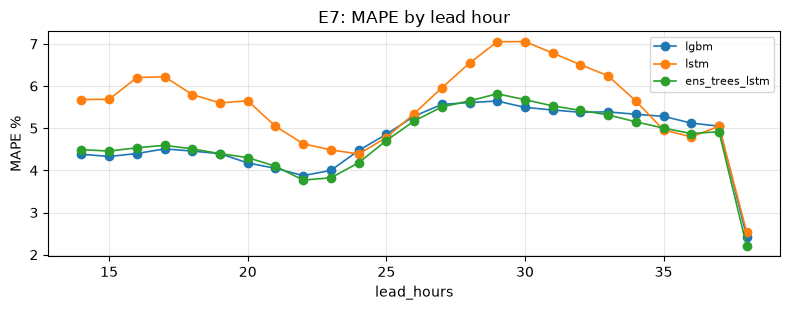

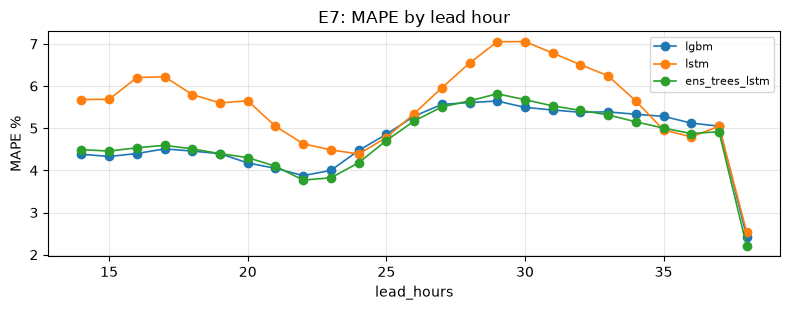

In [4]:
for label in ["trees", "trees_lstm"]:
    report.log_scored(f"E7_ensemble_{label}", oof, f"ens_{label}",
                      {"model": f"ensemble_{label}", "members": [MEMBERS[m] for m in (["lgbm", "catboost", "xgb"] if label == "trees" else MEMBERS)],
                       "weights": "hill-climb on MAPE, leave-one-fold-out"},
                      dicts={"weights_per_fold": blends[label]}, tags={"experiment": "E7"})
plots.compare_by(oof, "lead_hours", ["lgbm", "lstm", "ens_trees_lstm"], "E7: MAPE by lead hour")

## E8 · Optuna on LightGBM + trend

40 trials of v1's search space, scored on pooled MAPE over the same three folds. Peak-MAPE is recorded for each trial.

In [5]:
def objective(trial):
    params = gbdt.search_space("lgbm", trial)
    r = cv.run_cv(cv.Spec("trial", lambda: gbdt.lgbm(**params), target="trend", features=features), tables, verbose=False)
    trial.set_user_attr("peak_mape", r.metrics["peak_mape"])
    trial.set_user_attr("minutes", r.seconds / 60)
    return r.metrics["mape"]

t0 = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42), study_name="lgbm_trend")
study.optimize(objective, n_trials=40)
trials = study.trials_dataframe()
print(f"{len(trials)} trials in {(time.time()-t0)/60:.0f} min; best MAPE {study.best_value:.3f}")
study.best_params

40 trials in 20 min; best MAPE 4.752


{'n_estimators': 722,
 'learning_rate': 0.04276283763327223,
 'num_leaves': 63,
 'max_depth': 7,
 'min_child_samples': 36,
 'subsample': 0.9041848157620341,
 'colsample_bytree': 0.8646598909189483,
 'reg_alpha': 9.041680725223594,
 'reg_lambda': 0.6592535142914678}

  E8_lgbm_trend_tuned          fold 1: MAPE 4.07%  peak 3.12%  (train 57,190 / val 8,760)


  E8_lgbm_trend_tuned          fold 2: MAPE 6.03%  peak 4.74%  (train 65,950 / val 8,784)


  E8_lgbm_trend_tuned          fold 3: MAPE 4.16%  peak 3.33%  (train 74,734 / val 8,760)


🏃 View run E8_lgbm_trend_tuned at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/0818b4c89ae440ceac59ac99d9d5015b
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape
lgbm default (E2),4.85,3.64,674.35,1.28,4.04,6.33,4.19
lgbm tuned (E8),4.75,3.73,652.29,1.02,4.07,6.03,4.16


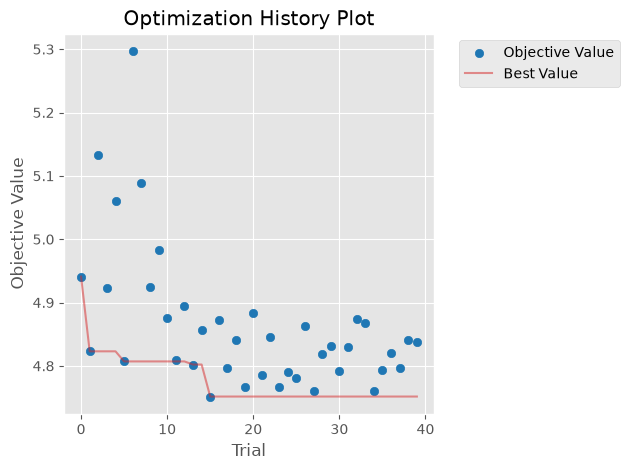

In [6]:
tuned_spec = cv.Spec("E8_lgbm_trend_tuned", lambda: gbdt.lgbm(**study.best_params), target="trend", features=features)
tuned = cv.run_cv(tuned_spec, tables)
fig_hist = optuna.visualization.matplotlib.plot_optimization_history(study).figure
report.log_result(tuned, figures={"optuna_history": fig_hist},
                  dicts={"best_params": study.best_params, "trials": trials.astype(str).to_dict("list")},
                  tags={"experiment": "E8"})
pd.concat([report.summary(oof, ["lgbm"]).rename(index={"lgbm": "lgbm default (E2)"}),
           report.summary(tuned.scored, ["pred"]).rename(index={"pred": "lgbm tuned (E8)"})])

## E9 · SHAP

This explains the tuned model's residual prediction: the part of load not explained by the trend line.

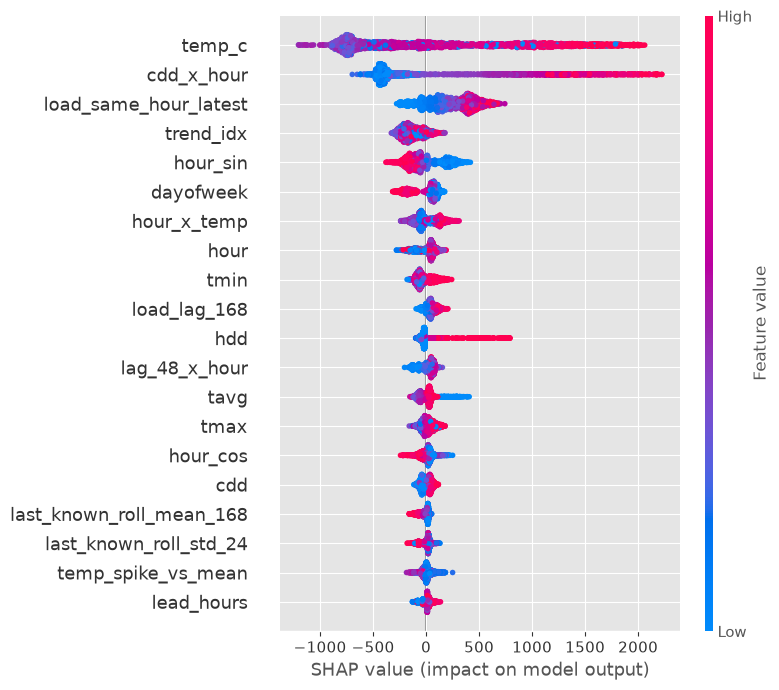

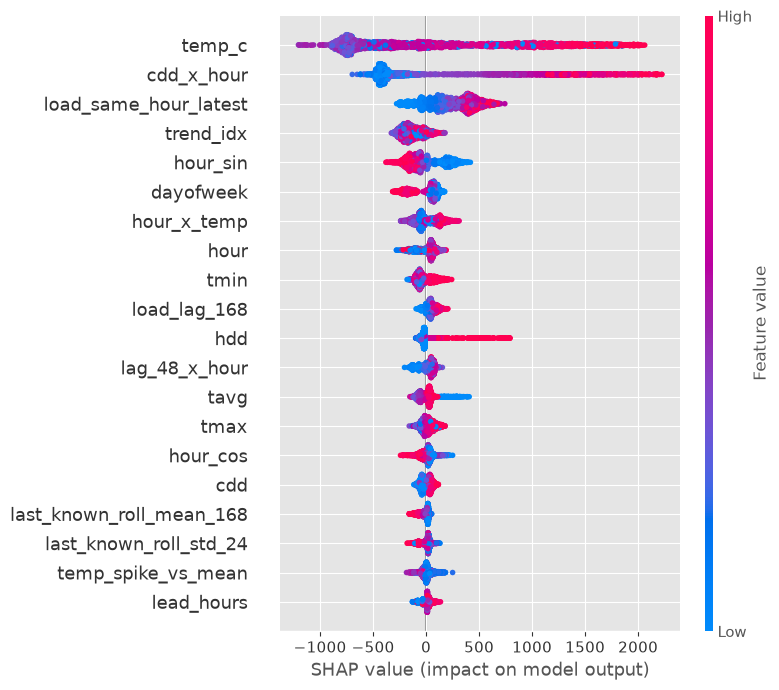

In [7]:
def shap_frame(fold, n=3000):
    model, target, bundle_ = tuned.models[fold]
    from shef.models import folds as F
    fd = data.fold_data(tables, F.FOLDS[fold - 1])
    X = fd.val[features].sample(min(n, len(fd.val)), random_state=0)
    return X, shap.TreeExplainer(model).shap_values(X)

X3, sv3 = shap_frame(3)
imp = pd.Series(np.abs(sv3).mean(axis=0), index=features).sort_values(ascending=False)
shap.summary_plot(sv3, X3, show=False, max_display=20)
fig_shap = plt.gcf(); fig_shap.set_size_inches(8, 7); fig_shap.tight_layout()
fig_shap

In [8]:
(imp / imp.max() * 100).round(1).to_frame("mean |SHAP|, % of top").head(45)

,"mean |SHAP|, % of top"
temp_c,100.0
cdd_x_hour,88.7
load_same_hour_latest,38.0
trend_idx,19.6
hour_sin,19.3
dayofweek,15.0
hour_x_temp,12.5
hour,10.1
tmin,9.6
load_lag_168,7.8


**The hard fold.** MAPE by daily max temperature for each fold shows whether fold 2's extra error sits in the heat.

In [9]:
sc = tuned.scored.merge(tables["proxy"][["ts_utc", "tmax"]], on="ts_utc")
sc["tmax_bin"] = pd.cut(sc["tmax"], [-20, 5, 15, 25, 32, 36, 38, 50])
heat = sc.assign(ape=(sc["pred"] - sc["y"]).abs() / sc["y"] * 100).pivot_table(index="tmax_bin", columns="fold", values="ape", aggfunc="mean").round(2)
heat_n = sc.pivot_table(index="tmax_bin", columns="fold", values="y", aggfunc="size")
display(heat); display(heat_n)

fold,1,2,3
tmax_bin,,,
"(-20, 5]",8.20,NaN,4.79
"(5, 15]",5.86,6.91,5.31
"(15, 25]",3.35,3.51,3.77
"(25, 32]",4.33,4.65,4.23
"(32, 36]",3.95,5.26,4.35
"(36, 38]",3.35,3.82,3.68
"(38, 50]",3.36,3.95,3.90


fold,1,2,3
tmax_bin,,,
"(-20, 5]",72.0,NaN,96.0
"(5, 15]",936.0,312.0,600.0
"(15, 25]",2088.0,2591.0,1631.0
"(25, 32]",2832.0,1969.0,2617.0
"(32, 36]",1320.0,1344.0,1920.0
"(36, 38]",216.0,984.0,960.0
"(38, 50]",1296.0,1104.0,936.0


In [10]:
bias_by_month = sc.assign(err=(sc["pred"] - sc["y"]) / sc["y"] * 100).pivot_table(index="month", columns="fold", values="err", aggfunc="mean").round(2)
bias_by_month

fold,1,2,3
month,,,
1,-2.72,16.53,-0.14
2,-2.16,2.72,-1.97
3,-1.25,3.37,1.12
4,-1.49,2.53,-0.37
5,-2.73,4.38,2.68
6,-0.36,0.30,1.77
7,-1.05,2.33,2.59
8,-0.67,2.10,-1.13
9,1.56,1.41,3.01


**Pruning.** Drop features whose mean |SHAP| is under 1% of the top feature's, then re-run once with the tuned parameters.

In [11]:
weak = imp[imp < 0.01 * imp.max()].index.tolist()
print("candidates to drop:", weak)
if weak:
    pruned_feats = [f for f in features if f not in weak]
    pruned = cv.run_cv(cv.Spec("E9_lgbm_trend_tuned_pruned", lambda: gbdt.lgbm(**study.best_params), target="trend",
                               features=pruned_feats), tables)
    report.log_result(pruned, figures={"shap_fold3": fig_shap}, dicts={"dropped": {"features": weak}}, tags={"experiment": "E9"})
    t9 = report.results_table({"tuned": tuned, "tuned_pruned": pruned})
    keep_pruned = report.champion(t9, FLOOR_PEAK) == "tuned_pruned"
else:
    t9, keep_pruned, pruned_feats = report.results_table({"tuned": tuned}), False, features
print("use pruned feature set:", keep_pruned)
t9

candidates to drop: ['holiday_freq', 'is_holiday', 'same_hour_age_h', 'dow_cos', 'is_monday', 'is_extreme_heat_event', 'load_staleness_h', 'is_extreme_cold_event']


  E9_lgbm_trend_tuned_pruned   fold 1: MAPE 4.21%  peak 3.09%  (train 57,190 / val 8,760)


  E9_lgbm_trend_tuned_pruned   fold 2: MAPE 6.11%  peak 4.89%  (train 65,950 / val 8,784)


  E9_lgbm_trend_tuned_pruned   fold 3: MAPE 4.23%  peak 3.33%  (train 74,734 / val 8,760)


🏃 View run E9_lgbm_trend_tuned_pruned at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/cda6c25c00ba4456ab8024fa0420aaf6
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


use pruned feature set: False


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape,minutes
tuned,4.75,3.73,652.29,1.02,4.07,6.03,4.16,0.41
tuned_pruned,4.85,3.77,648.50,1.02,4.21,6.11,4.23,0.35


## E10 · Weather model: `best_match` vs `gfs_seamless`

Only the archived forecast changes. The same tuned model is trained per fold on `obs` and validated on proxy features rebuilt from GFS-only forecasts.

In [12]:
t0 = time.time()
final_feats = pruned_feats if keep_pruned else features
joined = store.read("clean", "joined")
gfs = weather_variants.proxy_variant("gfs_seamless", date(2022, 7, 25), date(2025, 8, 11))
proxy_gfs = replay(weather_variants.joined_with(joined, gfs), date(2022, 8, 10), date(2025, 8, 9), "proxy")
tables_gfs = {"obs": tables["obs"], "proxy": proxy_gfs[tables["proxy"].columns]}
print(f"rebuilt GFS proxy in {(time.time()-t0)/60:.1f} min; temp_c missing {proxy_gfs['temp_c'].isna().mean():.2%}")
spec10 = lambda name, t: cv.run_cv(cv.Spec(name, lambda: gbdt.lgbm(**study.best_params), target="trend", features=final_feats), t)
e10 = {"best_match": spec10("E10_best_match", tables), "gfs_seamless": spec10("E10_gfs_seamless", tables_gfs)}
for k, r in e10.items():
    report.log_result(r, tags={"experiment": "E10", "weather_model": k})
report.results_table(e10)

rebuilt GFS proxy in 2.1 min; temp_c missing 1.92%


  E10_best_match               fold 1: MAPE 4.07%  peak 3.12%  (train 57,190 / val 8,760)


  E10_best_match               fold 2: MAPE 6.03%  peak 4.74%  (train 65,950 / val 8,784)


  E10_best_match               fold 3: MAPE 4.16%  peak 3.33%  (train 74,734 / val 8,760)


  E10_gfs_seamless             fold 1: MAPE 4.07%  peak 3.12%  (train 57,190 / val 8,760)


  E10_gfs_seamless             fold 2: MAPE 6.03%  peak 4.74%  (train 65,950 / val 8,784)


  E10_gfs_seamless             fold 3: MAPE 4.16%  peak 3.33%  (train 74,734 / val 8,760)


🏃 View run E10_best_match at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/b147f616c4224773b6f260a0dc69dfee
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


🏃 View run E10_gfs_seamless at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/efe3a8f69d014cde8656068e6012e8b6
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape,minutes
best_match,4.75,3.73,652.29,1.02,4.07,6.03,4.16,0.39
gfs_seamless,4.75,3.73,652.29,1.02,4.07,6.03,4.16,0.41


## Selection for notebook 05

In [13]:
ens_row = report.summary(oof, ["ens_trees_lstm"]).loc["ens_trees_lstm"]
cands = report.results_table({"lgbm_tuned": e10["best_match"]})
cands.loc["ensemble_trees_lstm", ["mape", "peak_mape"]] = [ens_row["mape"], ens_row["peak_mape"]]
display(cands[["mape", "peak_mape"]])
weather_model = report.champion(report.results_table(e10), FLOOR_PEAK)
selection = {
    "model": "lgbm", "target": "trend", "train_source": "obs", "uri": "exclude",
    "params": study.best_params, "features": final_feats, "weather_model": weather_model,
    "cv_mape": e10["best_match"].metrics["mape"], "cv_peak_mape": e10["best_match"].metrics["peak_mape"],
    "ensemble_cv_mape": float(ens_row["mape"]), "ensemble_cv_peak_mape": float(ens_row["peak_mape"]),
}
(REPORTS / "p3_selection.json").write_text(json.dumps(selection, indent=2))
selection

,mape,peak_mape
lgbm_tuned,4.75,3.73
ensemble_trees_lstm,4.83,3.65


{'model': 'lgbm',
 'target': 'trend',
 'train_source': 'obs',
 'uri': 'exclude',
 'params': {'n_estimators': 722,
  'learning_rate': 0.04276283763327223,
  'num_leaves': 63,
  'max_depth': 7,
  'min_child_samples': 36,
  'subsample': 0.9041848157620341,
  'colsample_bytree': 0.8646598909189483,
  'reg_alpha': 9.041680725223594,
  'reg_lambda': 0.6592535142914678},
 'features': ['hour',
  'dayofweek',
  'month',
  'is_weekend',
  'is_monday',
  'hour_sin',
  'hour_cos',
  'dow_sin',
  'dow_cos',
  'is_holiday',
  'holiday_freq',
  'trend_idx',
  'lead_hours',
  'temp_c',
  'tmax',
  'tmin',
  'tavg',
  'cdd',
  'hdd',
  'cdd_x_hour',
  'hour_x_temp',
  'temp_spike_vs_mean',
  'is_extreme_heat_event',
  'is_extreme_cold_event',
  'tmax_roll_max_72',
  'temp_c_roll_std_72',
  'tavg_lag_24',
  'tmax_lag_24',
  'tmin_lag_24',
  'load_same_hour_latest',
  'same_hour_age_h',
  'load_lag_48',
  'lag_48_x_hour',
  'load_lag_168',
  'last_known_load',
  'load_staleness_h',
  'dminus1_vs_lastweek

## Reading, and a correction found after this notebook ran

**The archived forecast has a 19-day hole: Dec 31 2023 → Jan 18 2024, 506 scored hours with no `temp_c`.**
- E9's bias-by-month table showed fold 2 January at **+16.5%**. Day by day, the forecast temperature is missing on exactly those days.
- The model was trained on ERA5, which is never missing, so it had never seen missing temperature. It fell back to a flat ~10.8 GW: 30–60% too high on mild days, and up to 23% too low during the Jan 15–17 cold snap.
- Serving would never predict without a forecast. **P4 needs a hard gate: no forecast temperature means no model prediction** (fall back to the baseline and raise an alert). These hours are now excluded from scoring (`data.fold_data`), the same way Uri is.
- **The "hard 2023–24 fold" was this hole, not the heat.** E9's MAPE-by-`tmax` table already showed fold 2 behaving normally in the heat.

**Re-scored on hours that have an archived forecast** (also logged as `*_with_forecast` metrics on every MLflow run):

| Candidate | MAPE | Peak-MAPE | Fold 2 |
|---|---|---|---|
| Floor `same_hour_latest` | 8.04% | 5.70% | 7.34% |
| **LightGBM + trend, default** | 4.18% | **2.99%** | 4.34% |
| LightGBM + trend, tuned (E8) | 4.14% | 3.04% | 4.21% |
| CatBoost + trend | 4.17% | 3.11% | 4.32% |
| XGBoost + trend | 4.23% | 2.98% | 4.21% |
| Trees ensemble, leave-one-fold-out (E7) | **4.12%** | 3.03% | 4.28% |
| Trees + LSTM ensemble | 4.16% | 3.01% | 4.28% |
| LSTM | 5.46% | 6.10% | 5.22% |

- **E7, E8: tuning and ensembling add only 0.04–0.06 points of MAPE.** That's within noise, and Optuna was tuned on these same folds, so its gain is optimistic. Under the tie rule (within 0.1 points, then better Peak-MAPE) the **plain default LightGBM + trend wins**: one model, default parameters, the simplest thing to serve.
- **E7: the LSTM doesn't help the blend.** Once the hole is excluded, its fold-2 advantage disappears.
- **E9: temperature and `cdd_x_hour` dominate the SHAP ranking.** Next come `load_same_hour_latest`, `trend_idx`, then hour, weekday and the temperature×hour interactions. Pruning the 8 weakest features made results worse (4.85 vs 4.75 on all hours), so all features stay.
- **E10: `gfs_seamless` gives exactly the same scores as `best_match`.** For temperature at these locations, the Previous Runs `best_match` archive *is* GFS. The live forecast API's `best_match` may blend other models (for example HRRR or NBM for the US). **Serving should request `models=gfs_seamless`** so live inputs match training. The live snapshot should start archiving it too.